# Stock Return Prediction: A Comparative Study of LSTM, GRU, 1D-CNN and LSTM + Company Embeddings on Nifty 50 Stocks

## Introduction

This notebook asks one question: **can a deep-learning model predict tomorrow's return of an Indian large-cap stock from the previous 30 days of returns?**

Four PyTorch models are compared, and every one of them is judged against two "do nothing" baselines:

1. **LSTM**: a recurrent network that reads the 30 days in order and keeps a memory of what it has seen
2. **GRU**: a lighter recurrent network (fewer gates, fewer parameters)
3. **1D-CNN**: a convolutional network that looks for short local patterns instead of reading in order
4. **LSTM + company embedding**: the LSTM plus a small learned "fingerprint" for each company

Baselines (no learning at all):

- **`naive_up`**: always predict the average daily return seen in training (a small positive number)
- **`zero`**: always predict 0%

Goal: does any neural network beat a constant guess? And whichever way the answer goes, how do we know it is not just luck? That is why the notebook uses baselines, a paired significance test, and repeated runs with different random seeds.

In [16]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


## Data

**Source:** Yahoo Finance through `yfinance`: daily closing prices from January 2015 to 30 September 2026. `auto_adjust=True` means prices are already corrected for stock splits, bonus issues and dividends, so a split does not show up as a fake 50% crash.

| Role | Companies |
|---|---|
| Training (6) | RELIANCE, TCS, HDFCBANK, ITC, LT, MARUTI |
| Held-out (2) | INFY, SBIN |

The six training companies cover different sectors (energy and retail, IT, banking, FMCG, engineering, autos). The two held-out companies are **never used in training, not even to compute the scaling**. They test whether a model learned something general about how stocks move, or only something specific to the six companies it saw.

No prices are missing (`isna().sum()` is 0 for every stock). `dropna()` stays as a safety net so that all stocks share exactly the same dates.

In [17]:
train_tickers   = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ITC.NS", "LT.NS", "MARUTI.NS"]
holdout_tickers = ["INFY.NS", "SBIN.NS"]
all_tickers = train_tickers + holdout_tickers

raw = yf.download(all_tickers, start="2015-01-01", end="2026-10-01", auto_adjust=True)["Close"]

print(raw.isna().sum())
raw = raw.dropna()

[*********************100%***********************]  8 of 8 completed

Ticker
HDFCBANK.NS    0
INFY.NS        0
ITC.NS         0
LT.NS          0
MARUTI.NS      0
RELIANCE.NS    0
SBIN.NS        0
TCS.NS         0
dtype: int64


## Daily returns

The models predict **returns**, not prices:

`return_t = (price_t - price_(t-1)) / price_(t-1)`

Why: prices drift upward over the years, and today's price is already an excellent guess for tomorrow's price, so *any* model looks accurate on a price chart (we show this later). Returns have no trend, sit on a similar scale for every stock, and are what a trader or risk manager actually cares about.

Reading the summary table below:

- The **average** daily return is tiny: about 0.03% to 0.08%.
- The **standard deviation** (a typical day's swing) is 1.4% to 2.0%.
- So the average is only about **2% to 5% of one day's standard deviation**. Any predictable part of tomorrow's return is roughly 20 to 50 times smaller than the random part.
- Single-day moves of 10% to 17% do occur, and SBIN has one day of +27.7%, which we double-check in the next section.

In [18]:
returns = raw.pct_change().dropna()
print(returns.describe())

Ticker  HDFCBANK.NS      INFY.NS       ITC.NS        LT.NS    MARUTI.NS  \
count   2904.000000  2904.000000  2904.000000  2904.000000  2904.000000   
mean       0.000511     0.000493     0.000295     0.000657     0.000622   
std        0.014034     0.016892     0.015319     0.016795     0.017070   
min       -0.126069    -0.161880    -0.128143    -0.162658    -0.169092   
25%       -0.006474    -0.008440    -0.007425    -0.008091    -0.007766   
50%        0.000365     0.000221    -0.000122     0.000000     0.000083   
75%        0.007190     0.009577     0.007969     0.008651     0.008705   
max        0.115996     0.120334     0.100456     0.141336     0.135149   

Ticker  RELIANCE.NS      SBIN.NS       TCS.NS  
count   2904.000000  2904.000000  2904.000000  
mean       0.000775     0.000636     0.000370  
std        0.016913     0.020368     0.015007  
min       -0.131539    -0.144040    -0.094103  
25%       -0.008563    -0.009395    -0.007343  
50%        0.000570     0.000389    

## Exploratory analysis

Three quick checks before any modelling: what the price history looks like, what daily returns look like, and whether past returns contain any pattern a model could learn.

### EDA 1: price history

*(Draft wording written before seeing this plot: confirm it matches your output, then delete this line.)*

Prices are rebased to 100 on the first day so all eight stocks fit on one chart. The y-axis is logarithmic, so equal percentage moves look equal.

What to notice: the stocks broadly move together (market-wide moves matter), and every stock drops sharply in March 2020 (the COVID-19 crash). That crash lies inside the training period.

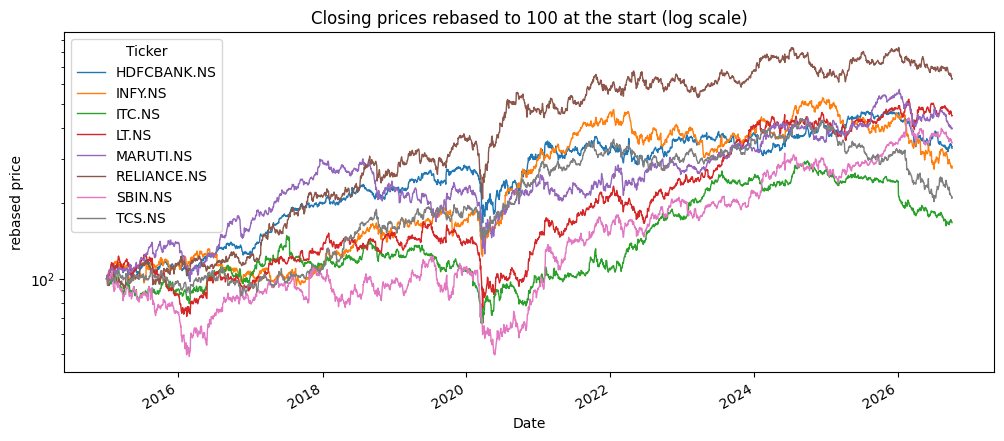

In [34]:
(raw / raw.iloc[0] * 100).plot(figsize=(12, 5), lw=1, logy=True,
    title="Closing prices rebased to 100 at the start (log scale)")
plt.ylabel("rebased price"); plt.show()

###2: what do daily returns look like?

*(Draft wording written before seeing this plot: confirm it matches your output, then delete this line.)*

The histograms pool the daily returns of all eight stocks. A normal (bell-curve) distribution has an *excess kurtosis* of 0. Stock returns have **fat tails**: most days are small, but a few days are huge. The log-scale histogram on the right makes those rare, large moves visible.

Two consequences for this project:

1. **MSE is dominated by a handful of extreme days.** One crash day can matter more than a hundred ordinary days, so small MSE gaps between models are easily moved by a few observations.
2. Nothing in the previous 30 returns can warn a model about a surprise (earnings, news, policy), so the biggest moves are essentially unpredictable for it.

The list of largest single-day moves is a **data-quality check**: each one should match a real market event, not a data glitch. The SBIN maximum of +27.7% in the summary table above deserves a look: find its date and confirm it against NSE or a news source.

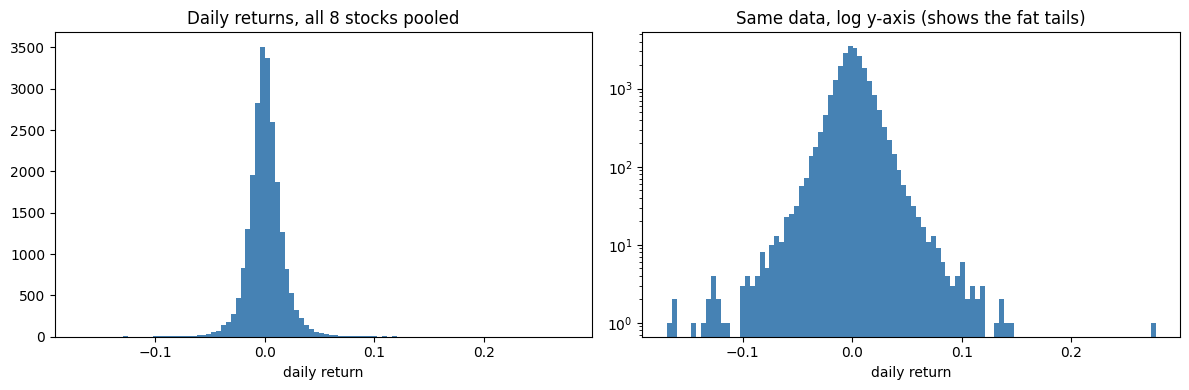

Excess kurtosis per stock (normal distribution = 0):
Ticker
HDFCBANK.NS     9.6
INFY.NS         8.0
ITC.NS         10.0
LT.NS           8.8
MARUTI.NS       9.6
RELIANCE.NS     8.4
SBIN.NS        16.2
TCS.NS          3.7
dtype: float64

Largest single-day moves (date, stock, return):
Date        Ticker     
2017-10-25  SBIN.NS        0.2769
2020-03-23  MARUTI.NS     -0.1691
            LT.NS         -0.1627
2019-10-22  INFY.NS       -0.1619
2020-03-25  RELIANCE.NS    0.1472
2024-06-04  SBIN.NS       -0.1440
2016-05-26  LT.NS          0.1413
2020-03-13  SBIN.NS        0.1383
dtype: float64


In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(returns.values.ravel(), bins=100, color="steelblue")
ax[0].set_title("Daily returns, all 8 stocks pooled"); ax[0].set_xlabel("daily return")
ax[1].hist(returns.values.ravel(), bins=100, color="steelblue"); ax[1].set_yscale("log")
ax[1].set_title("Same data, log y-axis (shows the fat tails)"); ax[1].set_xlabel("daily return")
plt.tight_layout(); plt.show()

print("Excess kurtosis per stock (normal distribution = 0):")
print(returns.kurt().round(1))

st = returns.stack()
print("\nLargest single-day moves (date, stock, return):")
print(st.loc[st.abs().sort_values(ascending=False).head(8).index].round(4))

### EDA 3: is there any pattern for a model to learn?

*(Draft wording written before seeing this plot: confirm it matches your output, then delete this line.)*

**Autocorrelation** is the correlation between today's return and the return `lag` days ago. If past returns helped predict future returns, the bars at lags 1 to 20 would stick out beyond the red dashed band (roughly the range pure chance produces for a single stock).

- **Left, returns:** the direction of a day's move.
- **Right, squared returns:** how *big* the move was, ignoring direction (a simple measure of volatility).

What this typically shows for stocks: the **direction** of returns has almost no memory, but the **size** of moves does. Calm days tend to follow calm days and wild days follow wild days (*volatility clustering*).

Why it matters: it sets our expectation before training. Predicting the direction or size of tomorrow's return from past returns is the hardest version of this problem. Predicting how volatile tomorrow will be is much easier, and we come back to that in the closing section.

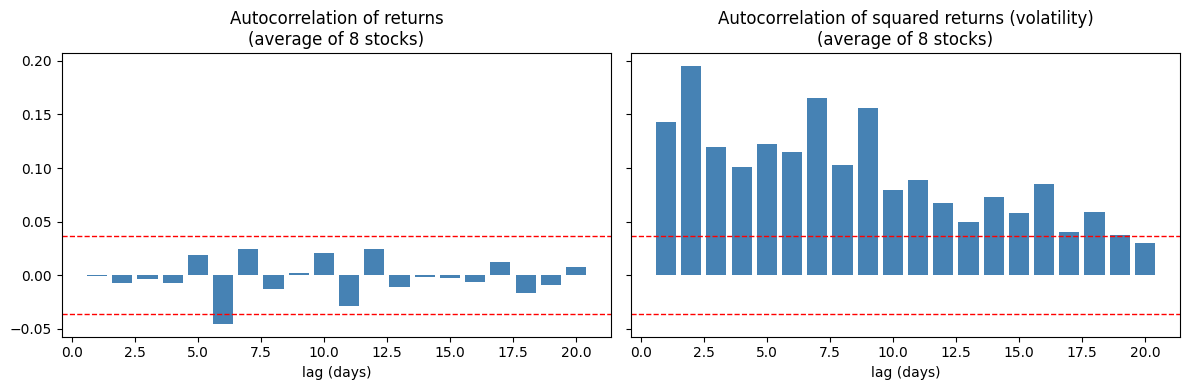

In [36]:
lags = range(1, 21)
acf = lambda s: [s.autocorr(l) for l in lags]
acf_ret = pd.DataFrame({t: acf(returns[t])      for t in returns}, index=lags).mean(axis=1)
acf_sq  = pd.DataFrame({t: acf(returns[t] ** 2) for t in returns}, index=lags).mean(axis=1)
band = 1.96 / np.sqrt(len(returns))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, vals, name in zip(ax, [acf_ret, acf_sq], ["returns", "squared returns (volatility)"]):
    a.bar(list(lags), vals.values, color="steelblue")
    a.axhline(band, c="r", ls="--", lw=1); a.axhline(-band, c="r", ls="--", lw=1)
    a.set_title(f"Autocorrelation of {name}\n(average of 8 stocks)"); a.set_xlabel("lag (days)")
plt.tight_layout(); plt.show()

## Preparing the data for the networks

### Windows: turning a return history into training examples

Every example is **input** = the previous 30 daily returns and **target** = the return on the next day.

Worked example for one stock: returns on days 1 to 30 predict day 31. Slide forward by one day: days 2 to 31 predict day 32, and so on. This is done separately for each stock, so a window never mixes two companies. (`WINDOW = 30`.) A window may reach back into the previous period (the first 2022 windows use late-2021 returns as input). That is fine, because it only uses the past.

### Scaling

Returns are standardised with `(return - mean) / std`, using **one mean and one std computed from the training period of the six training stocks only**.

- Using only training data avoids leakage: if test-period numbers helped set the scale, test information would sneak into training.
- One shared scale (instead of one per stock) keeps differences in volatility visible to the model.
- Predictions are converted back to real returns with `* std + mu`, so all metrics below are in real return units.

### Chronological split

| Split | Period | Stocks | Samples | Used for |
|---|---|---|---|---|
| Train | Jan 2015 to Dec 2021 | 6 training stocks | 10,182 | learning the weights |
| Validation | 2022 | 6 training stocks | 1,488 | deciding when to stop training |
| Test, "seen" | Jan 2023 to Sep 2026 | 6 training stocks | 5,574 | same companies, future dates |
| Test, "held-out" | Jan 2023 to Sep 2026 | INFY, SBIN | 1,858 | new companies, same future dates |

Why chronological and not a random shuffle: a shuffled split lets the model train on days *after* some of its test days, which is looking into the future.

Why two test sets: both cover the same dates, so any difference between "seen" and "held-out" comes only from the company. That separates "does it generalise in time" from "does it generalise to new companies".

The last line of the cell below creates the first baseline, `naive_up`.

In [19]:
WINDOW, TRAIN_END, VAL_END, TEST_START = 30, "2021-12-31", "2022-12-31", "2023-01-01"

train_mask = returns.index <= TRAIN_END
mu  = returns.loc[train_mask, train_tickers].values.mean()
std = returns.loc[train_mask, train_tickers].values.std()
scaled = (returns - mu) / std

def build(tickers, start, end):
    Xs, ys, ms = [], [], []
    dates = scaled.index
    start, end = pd.Timestamp(start), pd.Timestamp(end)

    for t in tickers:
        s = scaled[t].values
        X, y, d = [], [], []

        for i in range(WINDOW, len(s)):
            if start <= dates[i] <= end:
                X.append(s[i - WINDOW : i])
                y.append(s[i])
                d.append(dates[i])

        Xs.append(np.array(X)); ys.append(np.array(y))
        ms.append(pd.DataFrame({"date": d, "ticker": t}))

    return np.concatenate(Xs), np.concatenate(ys), pd.concat(ms, ignore_index=True)

t0, t1 = returns.index[0], returns.index[-1]
D = {
    "train": build(train_tickers,   t0,           TRAIN_END),
    "val":   build(train_tickers,   "2022-01-01", VAL_END),
    "seen":  build(train_tickers,   TEST_START,   t1),
    "held":  build(holdout_tickers, TEST_START,   t1),
}
T = {s: D[s][1] * std + mu for s in D}
for s, (X, y, m) in D.items():
    print(s, X.shape)

P = {}
P["naive_up"] = {s: np.full(len(T[s]), max(mu, 1e-6)) for s in ["val", "seen", "held"]}

train (10182, 30)
val (1488, 30)
seen (5574, 30)
held (1858, 30)


## PyTorch setup

- `device` selects the GPU if one is available, otherwise the CPU.
- `tt` turns a NumPy array into a PyTorch tensor of 32-bit floats, the number format networks expect.

In [20]:
device = "cuda" if torch.cuda.is_available() else "cpu"
tt = lambda a: torch.tensor(a, dtype=torch.float32)

## The models

All the networks have the same shape: **encoder → dropout → one linear layer → one number** (the predicted next-day scaled return). Only the *encoder*, the part that reads the 30 days, differs. That keeps the comparison fair.

### LSTM (Long Short-Term Memory)

Reads the 30 returns one day at a time, oldest first, and carries two things forward: a *hidden state* (a short-term summary) and a *cell state* (long-term memory). At every day, three gates (numbers between 0 and 1) decide what happens to the memory:

- **forget gate**: how much of the old memory to erase
- **input gate**: how much of today's return to write into memory
- **output gate**: how much of the memory to show as today's summary

After day 30, the hidden state (64 numbers) is the model's summary of the whole window.

### GRU (Gated Recurrent Unit)

The same idea with two gates and no separate cell state. It has about 25% fewer parameters than the LSTM (roughly 12,900 versus 17,200 including the output layer).

### 1D-CNN

Does not read in order. It slides small filters (3 days wide) across the window to detect short patterns such as "down, down, up", does this twice, then averages over time to get 64 numbers. It is the smallest model, with about 6,400 parameters.

### What happens inside `forward` (batch of 64 windows)

| Step | Code | Shape | Meaning |
|---|---|---|---|
| input | `x` | (64, 30) | 64 windows of 30 returns |
| add a feature axis | `x.unsqueeze(-1)` | (64, 30, 1) | 1 number per day, as the LSTM expects |
| recurrent layer | `self.body(...)[0]` | (64, 30, 64) | a 64-number summary after every day |
| keep the last day | `[:, -1]` | (64, 64) | the summary after reading all 30 days |
| dropout | `self.drop(h)` | (64, 64) | randomly zeroes 20% of values, only while training |
| linear layer | `self.fc(...)` | (64, 1) | 64 numbers become 1 |
| drop the last axis | `.squeeze(-1)` | (64,) | one prediction per window |

For the CNN, `x.unsqueeze(1)` gives shape (64, 1, 30), because convolutions expect channels first. The pooling layer then collapses the 30 days into one.

### Training (`fit_predict`)

| Setting | Value |
|---|---|
| Loss | MSE (mean squared error) |
| Optimiser | Adam, learning rate 0.001 |
| Batch size | 64 |
| Maximum epochs | 50 |
| Early stopping | patience 5 |
| Hidden size / dropout | 64 / 0.2 |
| Random seed | 42 |

For every batch of 64 windows:

1. `opt.zero_grad()`: clear the gradients left over from the last batch
2. `model(xb)`: forward pass, get predictions
3. `lf(model(xb), yb)`: compute the MSE loss
4. `.backward()`: backpropagation, work out how each weight affects the loss
5. `opt.step()`: Adam nudges every weight slightly in the helpful direction

After each epoch (one full pass over the 10,182 training windows) the model switches to evaluation mode (dropout off) and its loss is measured on the 2022 validation data. If the validation loss improves, a copy of the weights is saved. If it fails to improve for 5 epochs in a row, training stops and the **best saved weights are reloaded**, so the model we evaluate is the one that was best on validation, not the last one trained.

The seed fixes the random starting weights and the shuffling order so results can be reproduced. Later we repeat everything with five other seeds.

In [21]:
class Net(nn.Module):
    def __init__(self, kind, hidden=64, dropout=0.2):
        super().__init__()
        self.kind = kind
        if kind in ("LSTM", "GRU"):
            self.body = {"LSTM": nn.LSTM, "GRU": nn.GRU}[kind](1, hidden, batch_first=True)
        else:
            self.body = nn.Sequential(
                nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(),
                nn.Conv1d(32, hidden, 3, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool1d(1))
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(hidden, 1)

    def forward(self, x):
        if self.kind == "CNN1D":
            h = self.body(x.unsqueeze(1)).squeeze(-1)
        else:
            h = self.body(x.unsqueeze(-1))[0][:, -1]
        return self.fc(self.drop(h)).squeeze(-1)

def fit_predict(kind, epochs=50, patience=5, lr=1e-3, seed=42):
    torch.manual_seed(seed)
    Xtr, ytr, _ = D["train"]; Xva, yva, _ = D["val"]
    dl = DataLoader(TensorDataset(tt(Xtr), tt(ytr)), batch_size=64, shuffle=True)
    model = Net(kind).to(device)
    opt, lf = torch.optim.Adam(model.parameters(), lr=lr), nn.MSELoss()
    best, state, wait = float("inf"), None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); lf(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val = lf(model(tt(Xva).to(device)), tt(yva).to(device)).item()
        print(f"{kind} epoch {ep+1:02d} val_loss {val:.5f}")
        if val < best:
            best, wait, state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        return {s: model(tt(D[s][0]).to(device)).cpu().numpy() * std + mu
                for s in ["val", "seen", "held"]}

for kind in ["LSTM", "GRU", "CNN1D"]:
    P[kind] = fit_predict(kind)

LSTM epoch 01 val_loss 0.85463
LSTM epoch 02 val_loss 0.85279
LSTM epoch 03 val_loss 0.85306
LSTM epoch 04 val_loss 0.85146
LSTM epoch 05 val_loss 0.85179
LSTM epoch 06 val_loss 0.85175
LSTM epoch 07 val_loss 0.85180
LSTM epoch 08 val_loss 0.85128
LSTM epoch 09 val_loss 0.85121
LSTM epoch 10 val_loss 0.85195
LSTM epoch 11 val_loss 0.85162
LSTM epoch 12 val_loss 0.85407
LSTM epoch 13 val_loss 0.85895
LSTM epoch 14 val_loss 0.85772
GRU epoch 01 val_loss 0.85296
GRU epoch 02 val_loss 0.85144
GRU epoch 03 val_loss 0.85152
GRU epoch 04 val_loss 0.85160
GRU epoch 05 val_loss 0.85125
GRU epoch 06 val_loss 0.85109
GRU epoch 07 val_loss 0.85216
GRU epoch 08 val_loss 0.85146
GRU epoch 09 val_loss 0.85119
GRU epoch 10 val_loss 0.85369
GRU epoch 11 val_loss 0.85285
CNN1D epoch 01 val_loss 0.85411
CNN1D epoch 02 val_loss 0.85353
CNN1D epoch 03 val_loss 0.85489
CNN1D epoch 04 val_loss 0.85392
CNN1D epoch 05 val_loss 0.85410
CNN1D epoch 06 val_loss 0.85392
CNN1D epoch 07 val_loss 0.85441


**Training result:** the validation loss is almost the same for all three models (about 0.851 to 0.855, in scaled units) and barely moves between the first epoch and the best one. For example the LSTM goes from 0.8546 to 0.8512. Early stopping ended training after 14 epochs for the LSTM (best at epoch 9), 11 for the GRU (best at epoch 6) and 7 for the 1D-CNN (best at epoch 2).

A network that found real structure would show the validation loss falling clearly for several epochs. Here the models learn the "average" almost immediately and then have nothing more to learn. This is a first hint, not proof. The baselines below make it precise.

### Variant: LSTM + company embedding

Question: does it help to tell the model *which company* it is looking at?

An **embedding** is a small lookup table that maps each company ID to a vector of 4 numbers, learned during training. These 4 numbers are joined to the LSTM's 64-number summary (64 + 4 = 68 numbers) before the final linear layer.

Problem: the held-out companies (INFY, SBIN) have no ID in training. Solution: an extra **UNKNOWN** ID (index 6). During training, 20% of examples have their true ID randomly replaced by UNKNOWN (`p_unk=0.2`, using `masked_fill`), so the model learns a sensible UNKNOWN vector. Held-out companies are always given UNKNOWN at test time.

In [22]:
tid = {t: i for i, t in enumerate(train_tickers)}
UNK = len(train_tickers)
get_ids = lambda s: torch.tensor([tid.get(t, UNK) for t in D[s][2].ticker])

class EmbLSTM(nn.Module):
    def __init__(self, hidden=64, emb_dim=4, dropout=0.2):
        super().__init__()
        self.rnn  = nn.LSTM(1, hidden, batch_first=True)
        self.emb  = nn.Embedding(UNK + 1, emb_dim)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(hidden + emb_dim, 1)

    def forward(self, x, ids):
        h = self.rnn(x.unsqueeze(-1))[0][:, -1]
        return self.fc(self.drop(torch.cat([h, self.emb(ids)], dim=1))).squeeze(-1)

def fit_predict_emb(epochs=50, patience=5, lr=1e-3, p_unk=0.2, seed=42):
    torch.manual_seed(seed)
    dl = DataLoader(TensorDataset(tt(D["train"][0]), tt(D["train"][1]), get_ids("train")),
                    batch_size=64, shuffle=True)
    Xva, yva, iva = tt(D["val"][0]).to(device), tt(D["val"][1]).to(device), get_ids("val").to(device)
    model = EmbLSTM().to(device)
    opt, lf = torch.optim.Adam(model.parameters(), lr=lr), nn.MSELoss()
    best, state, wait = float("inf"), None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb, ib in dl:
            xb, yb, ib = xb.to(device), yb.to(device), ib.to(device)
            ib = ib.masked_fill(torch.rand(len(ib), device=device) < p_unk, UNK)
            opt.zero_grad(); lf(model(xb, ib), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val = lf(model(Xva, iva), yva).item()
        print(f"Emb epoch {ep+1:02d} val_loss {val:.5f}")
        if val < best:
            best, wait, state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        return {s: model(tt(D[s][0]).to(device), get_ids(s).to(device)).cpu().numpy() * std + mu
                for s in ["val", "seen", "held"]}

P["LSTM+Emb"] = fit_predict_emb()

Emb epoch 01 val_loss 0.85342
Emb epoch 02 val_loss 0.85217
Emb epoch 03 val_loss 0.85221
Emb epoch 04 val_loss 0.85392
Emb epoch 05 val_loss 0.85300
Emb epoch 06 val_loss 0.85294
Emb epoch 07 val_loss 0.85160
Emb epoch 08 val_loss 0.85178
Emb epoch 09 val_loss 0.85198
Emb epoch 10 val_loss 0.85343
Emb epoch 11 val_loss 0.85283
Emb epoch 12 val_loss 0.85452


**Training result:** early stopping ended training after 12 epochs (best at epoch 7, validation loss 0.8516), in the same range as the other models.

## Evaluation

All numbers from here on use the test period (January 2023 onwards), which was never touched during training or early stopping. For each model, on seen and held-out companies:

- **`dir_acc`** (directional accuracy): the share of days on which the predicted sign (up or down) matches the real one.
- **`rmse`**: the typical size of the error, in return units (0.0134 means 1.34 percentage points).
- **`pct_up`**: the share of days on which the model predicted "up". If this is close to 100%, the model says almost the same thing every day.

The key reference point is the **always-up baseline**: its accuracy is simply the share of days the stock really rose (49.28% seen, 50.27% held-out). A model is only useful if it clearly beats *that* number, not just 50%. (Days with exactly 0.00% return count as wrong for every model, which is one reason the baseline sits just under 50%.)

**Result:**

- Every network's directional accuracy is within about half a percentage point of the always-up baseline (seen: 48.8% to 49.4% against 49.3%; held-out: 50.2% to 50.5% against 50.3%).
- RMSE is identical to four decimals for every model, baseline included (1.34% seen, 1.56% held-out).
- `pct_up` is 96% to 100%: the networks predict "up" on almost every day, which is the same as predicting a small average return.
- In the plots, the top panel shows the predictions as an almost flat line near zero while the actual returns swing between about -2% and +3%. The bottom panel shows all four models with the same rolling accuracy, because they predict the same sign. The middle panel (price level) looks excellent for every model, but that is misleading: a single day's price change is only 1% to 2%, so "tomorrow's price = today's price" already looks perfect. It is **not** evidence of skill.

## Mean squared error and "skill" against the baseline

Directional accuracy looks only at the sign. **MSE** is the average of `(prediction - actual)²`, so it also punishes big misses. Lower is better. Values are shown multiplied by 1e-4 to keep the numbers readable.

**Skill score** = `(1 - MSE_model / MSE_naive_up) × 100%`. Positive means better than the constant guess, 0 means the same, negative means worse than doing nothing.

The `zero` baseline (always predict 0%) is added as a second yardstick. It can beat `naive_up` slightly if the average return in the test period was lower than in the training period.

always-up baseline  seen: 0.4928  held: 0.5027


dir_acc            rmse          pct_up        
split       held    seen    held    seen    held    seen
model                                                   
CNN1D     0.5027  0.4937  0.0156  0.0134  1.0000  0.9987
GRU       0.5027  0.4916  0.0156  0.0134  0.9935  0.9955
LSTM      0.5048  0.4925  0.0156  0.0134  0.9774  0.9806
LSTM+Emb  0.5022  0.4878  0.0156  0.0134  0.9930  0.9595
naive_up  0.5027  0.4928  0.0156  0.0134  1.0000  1.0000

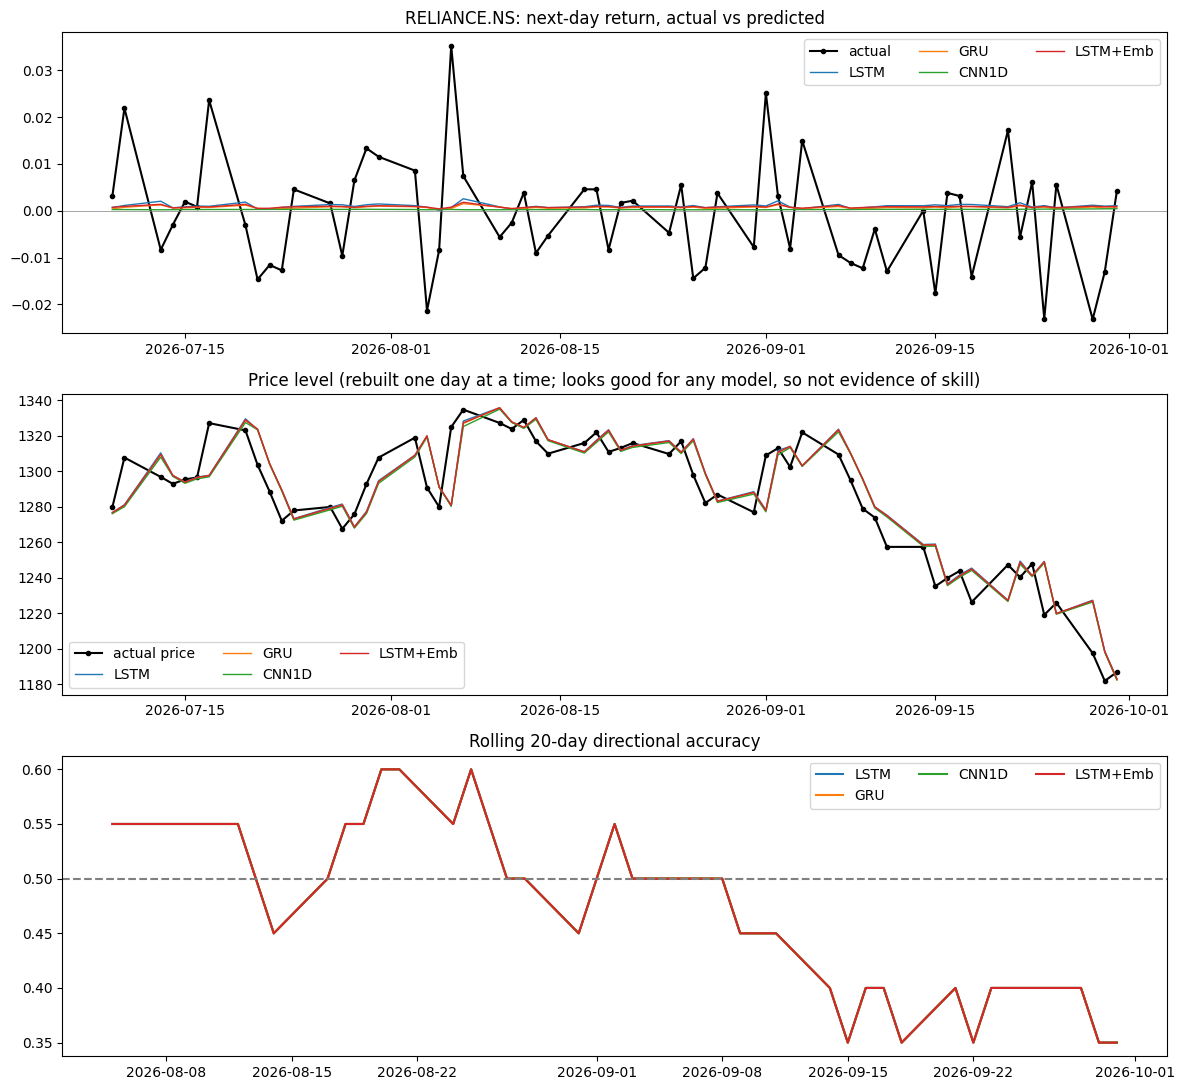

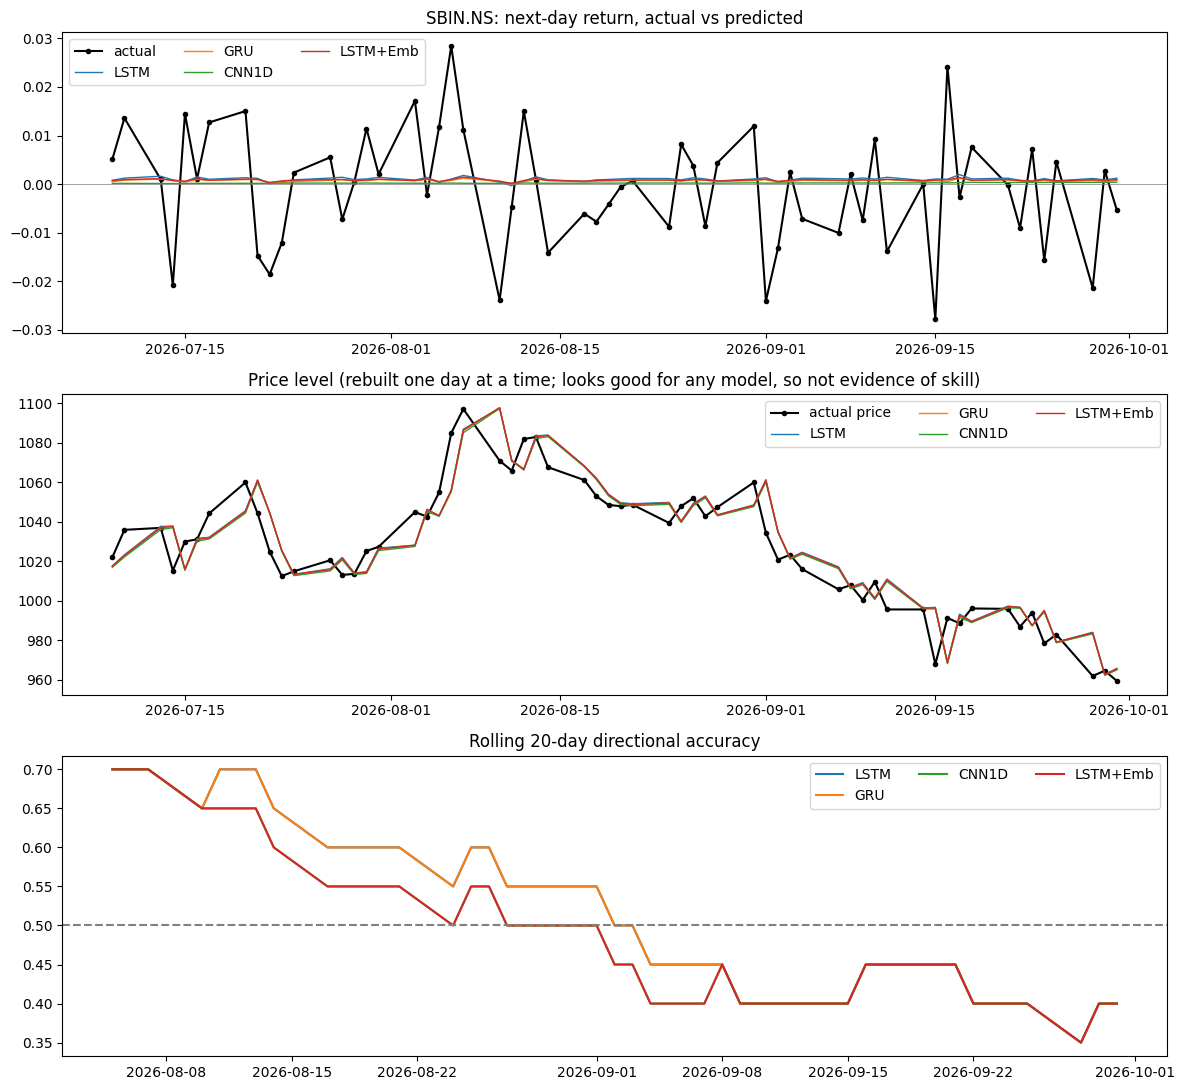

In [23]:
def metrics():
    rows = []
    for name, p in P.items():
        for s in ["seen", "held"]:
            rows.append(dict(model=name, split=s,
                             dir_acc=(np.sign(p[s]) == np.sign(T[s])).mean(),
                             rmse=np.sqrt(((p[s] - T[s]) ** 2).mean()),
                             pct_up=(p[s] > 0).mean()))
    return pd.DataFrame(rows).pivot(index="model", columns="split",
                                    values=["dir_acc", "rmse", "pct_up"]).round(4)

print("always-up baseline  seen:", (T["seen"] > 0).mean().round(4), " held:", (T["held"] > 0).mean().round(4))
display(metrics())

def plot_ticker(ticker, split, models=None, last_n=60):
    models = models or [m for m in P if m != "naive_up"]
    m = D[split][2]; idx = np.where(m.ticker == ticker)[0][-last_n:]
    d = m.date.values[idx]
    fig, ax = plt.subplots(3, 1, figsize=(12, 11))

    ax[0].plot(d, T[split][idx], "k-o", ms=3, lw=1.5, label="actual")
    for name in models: ax[0].plot(d, P[name][split][idx], lw=1, label=name)
    ax[0].axhline(0, c="gray", lw=.5); ax[0].set_title(f"{ticker}: next-day return, actual vs predicted"); ax[0].legend(ncol=3)

    prev = raw[ticker].shift(1).loc[pd.to_datetime(d)].values
    ax[1].plot(d, prev * (1 + T[split][idx]), "k-o", ms=3, label="actual price")
    for name in models: ax[1].plot(d, prev * (1 + P[name][split][idx]), lw=1, label=name)
    ax[1].set_title("Price level (rebuilt one day at a time; looks good for any model, so not evidence of skill)"); ax[1].legend(ncol=3)

    for name in models:
        hit = pd.Series(np.sign(P[name][split][idx]) == np.sign(T[split][idx]))
        ax[2].plot(d, hit.rolling(20).mean(), label=name)
    ax[2].axhline(.5, c="gray", ls="--"); ax[2].set_title("Rolling 20-day directional accuracy"); ax[2].legend(ncol=3)
    plt.tight_layout(); plt.show()

plot_ticker("RELIANCE.NS", "seen")
plot_ticker("SBIN.NS", "held")

**Result** (table sorted by held-out MSE):

- All gaps are tiny: skill scores run from -0.52% to +0.13%.
- The lowest MSE belongs to the `zero` baseline (held-out) and to the 1D-CNN (seen, by 0.0001), but only by about 0.1%.
- The LSTM is worst (-0.52% seen, -0.49% held-out), then LSTM + Emb, then GRU. That order matches model size (LSTM and LSTM + Emb about 17,000 parameters, GRU about 13,000, CNN about 6,400), which is consistent with bigger models fitting more noise.
- A "0.13% better than doing nothing" is not evidence of skill. The next test asks whether gaps this small are larger than random noise.

## Mean squared error and "skill" against the baseline

Directional accuracy looks only at the sign. **MSE** is the average of `(prediction - actual)²`, so it also punishes big misses. Lower is better. Values are shown multiplied by 1e-4 to keep the numbers readable.

**Skill score** = `(1 - MSE_model / MSE_naive_up) × 100%`. Positive means better than the constant guess, 0 means the same, negative means worse than doing nothing.

The `zero` baseline (always predict 0%) is added as a second yardstick. It can beat `naive_up` slightly if the average return in the test period was lower than in the training period.

In [24]:
splits = ["seen", "held"]

P["zero"] = {s: np.zeros(len(T[s])) for s in ["val", "seen", "held"]}

def mse(p, t):
    return np.mean((p - t) ** 2)

rows = []
for name, p in P.items():
    row = {"model": name}
    for s in splits:
        row[f"MSE_{s} (x1e-4)"]  = mse(p[s], T[s]) * 1e4
        row[f"skill_{s} (%)"]    = (1 - mse(p[s], T[s]) / mse(P["naive_up"][s], T[s])) * 100
    rows.append(row)

mse_table = pd.DataFrame(rows).set_index("model").sort_values("MSE_held (x1e-4)")
display(mse_table.round(4))

,MSE_seen (x1e-4),skill_seen (%),MSE_held (x1e-4),skill_held (%)
model,,,,
zero,1.7851,0.1276,2.4346,0.0691
CNN1D,1.7850,0.1347,2.4350,0.0536
naive_up,1.7874,0.0000,2.4363,0.0000
GRU,1.7893,-0.1094,2.4389,-0.1067
LSTM+Emb,1.7909,-0.1993,2.4429,-0.2706
LSTM,1.7966,-0.5160,2.4483,-0.4928


**Result** (table sorted by held-out MSE):

- All gaps are tiny: skill scores run from -0.52% to +0.13%.
- The lowest MSE belongs to the `zero` baseline (held-out) and to the 1D-CNN (seen, by 0.0001), but only by about 0.1%.
- The LSTM is worst (-0.52% seen, -0.49% held-out), then LSTM + Emb, then GRU. That order matches model size (LSTM and LSTM + Emb about 17,000 parameters, GRU about 13,000, CNN about 6,400), which is consistent with bigger models fitting more noise.
- A "0.13% better than doing nothing" is not evidence of skill. The next test asks whether gaps this small are larger than random noise.

## Is a difference real? Paired test against `naive_up`

Comparing two MSE numbers is not enough: a model can look slightly better just by luck on this particular set of days. So for every date we compute the **average squared-error difference** `(model - naive_up)` across the stocks, then ask whether the mean of those daily differences is clearly different from zero.

- `diff_vs_naive`: mean difference in MSE (x1e-4). Negative means the model is better.
- `std_error`: how much that mean would wobble by chance.
- `t_stat = diff / std_error`. As a rule of thumb, a t-stat bigger than 2 in absolute value is unlikely (about 5%) to be pure chance. Smaller than 2 means "no clear difference".

Worked example: if a model is better by 0.001 on average but the day-to-day differences swing by plus or minus 0.05, the gain is buried in noise and the t-stat will be near 0.

In [29]:
def paired_vs_naive(name, s):
    err_m = (P[name][s] - T[s]) ** 2
    err_b = (P["naive_up"][s] - T[s]) ** 2
    d = pd.Series(err_m - err_b).groupby(D[s][2]["date"].values).mean()
    mean, se = d.mean(), d.std() / np.sqrt(len(d))
    return mean * 1e4, se * 1e4, mean / se

rows = []
for name in [m for m in P if m != "naive_up"]:
    for s in splits:
        diff, se, t = paired_vs_naive(name, s)
        verdict = "no clear difference" if abs(t) < 2 else ("better than naive" if diff < 0 else "worse than naive")
        rows.append(dict(model=name, split=s, diff_vs_naive=diff, std_error=se, t_stat=t, verdict=verdict))

paired = pd.DataFrame(rows)
display(paired.round(4))

,model,split,diff_vs_naive,std_error,t_stat,verdict
0,LSTM,seen,0.0092,0.0044,2.1026,worse than naive
1,LSTM,held,0.0120,0.0104,1.1579,no clear difference
2,GRU,seen,0.0020,0.0019,1.0102,no clear difference
3,GRU,held,0.0026,0.0051,0.5070,no clear difference
4,CNN1D,seen,-0.0024,0.0021,-1.1460,no clear difference
5,CNN1D,held,-0.0013,0.0028,-0.4690,no clear difference
6,LSTM+Emb,seen,0.0036,0.0023,1.5578,no clear difference
7,LSTM+Emb,held,0.0066,0.0066,0.9949,no clear difference
8,zero,seen,-0.0023,0.0039,-0.5866,no clear difference
9,zero,held,-0.0017,0.0054,-0.3095,no clear difference


**Result:** only one of the ten rows passes the t-stat 2 mark: the LSTM on seen companies (t = 2.10), and in the **wrong** direction (worse than `naive_up` by 0.0092 x1e-4). Every other row has a t-stat below 1.6 in absolute value, so there is no clear difference from the baseline.

Two caveats:

1. Ten comparisons were made, and each has a roughly 1-in-20 chance of crossing 2 by luck, so one borderline hit is not surprising.
2. This table uses a single seed (42). The multi-seed table at the end shows that seed 42 was an unusually bad run for the LSTM, so its t = 2.10 is somewhat exaggerated.

## Does it differ by company?

MSE per stock for each model, so one company cannot hide the pattern of the others.

In [37]:
rows = []
for s in splits:
    m = D[s][2]
    for tk in m.ticker.unique():
        idx = (m.ticker == tk).values
        row = {"split": s, "ticker": tk}
        for name in P:
            row[name] = mse(P[name][s][idx], T[s][idx]) * 1e4
        rows.append(row)

per_company = pd.DataFrame(rows).set_index(["split", "ticker"])
display(per_company.round(4))

naive_up    LSTM     GRU   CNN1D  LSTM+Emb    zero
split ticker                                                         
seen  RELIANCE.NS    1.6715  1.6787  1.6724  1.6679    1.6753  1.6681
      TCS.NS         2.0246  2.0392  2.0282  2.0195    2.0277  2.0158
      HDFCBANK.NS    1.5481  1.5606  1.5509  1.5444    1.5555  1.5428
      ITC.NS         1.3749  1.3879  1.3784  1.3721    1.3773  1.3702
      LT.NS          2.3336  2.3453  2.3380  2.3336    2.3433  2.3398
      MARUTI.NS      1.7717  1.7678  1.7681  1.7723    1.7665  1.7739
held  INFY.NS        2.6325  2.6382  2.6310  2.6301    2.6351  2.6247
      SBIN.NS        2.2401  2.2584  2.2468  2.2399    2.2507  2.2446

**Result:** no model wins consistently. The `zero` baseline has the lowest MSE for 4 of the 8 companies (TCS, HDFCBANK, ITC, INFY), the 1D-CNN for RELIANCE and SBIN, `naive_up` ties with the CNN for LT, and LSTM + Emb is best for MARUTI. All of those margins are in the third decimal place.

The differences **between stocks** (MSE from 1.37 to 2.63) are far larger than the differences **between models** within a stock. MSE mostly measures how volatile the stock is, not how good the model is.**Result:** no model wins consistently. The `zero` baseline has the lowest MSE for 4 of the 8 companies (TCS, HDFCBANK, ITC, INFY), the 1D-CNN for RELIANCE and SBIN, `naive_up` ties with the CNN for LT, and LSTM + Emb is best for MARUTI. All of those margins are in the third decimal place.

The differences **between stocks** (MSE from 1.37 to 2.63) are far larger than the differences **between models** within a stock. MSE mostly measures how volatile the stock is, not how good the model is.

## Information coefficient (IC)

IC is the **Spearman rank correlation** between the predicted and actual returns. It asks: when the model predicts a higher return than usual, is the real return also higher than usual? IC is 0 for no relationship, +1 for a perfect ranking, and negative if the model points the wrong way.

Reference point: with this many test days, pure noise produces an IC of roughly plus or minus 0.013 (seen, 5,574 samples) or plus or minus 0.023 (held-out, 1,858 samples). As a rule of thumb, practitioners look for values of about 0.02 to 0.05 that stay stable over time. Note that this IC is pooled over all stocks and days.

In [31]:
from scipy.stats import spearmanr

ic = {}
for name in P:
    if name in ("naive_up", "zero"):
        continue
    ic[name] = {s: spearmanr(P[name][s], T[s])[0] for s in splits}

display(pd.DataFrame(ic).T.rename(columns={"seen": "IC_seen", "held": "IC_held"}).round(4))

,IC_seen,IC_held
LSTM,-0.0042,0.0108
GRU,-0.0053,0.0060
CNN1D,-0.0014,-0.0046
LSTM+Emb,-0.0062,0.0117


**Result:** every IC is between -0.006 and +0.012, inside the noise band, and the sign flips between seen and held-out for three of the four models. There is no ranking signal.

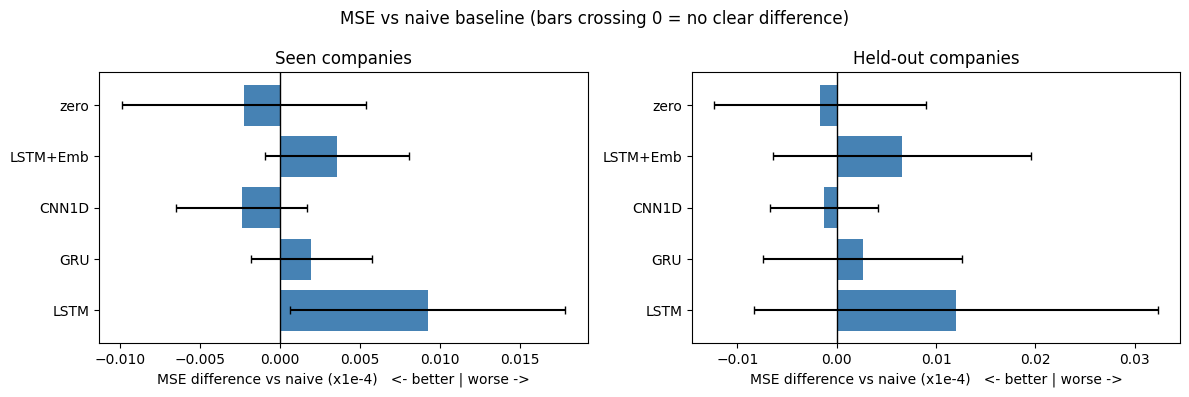

In [32]:
names = [m for m in P if m != "naive_up"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

for ax, s in zip(axes, splits):
    diffs, ses = [], []
    for name in names:
        d, se, _ = paired_vs_naive(name, s)
        diffs.append(d); ses.append(1.96 * se)
    ax.barh(names, diffs, xerr=ses, color="steelblue", capsize=3)
    ax.axvline(0, color="k", lw=1)
    ax.set_title(f"{'Seen' if s == 'seen' else 'Held-out'} companies")
    ax.set_xlabel("MSE difference vs naive (x1e-4)   <- better | worse ->")
plt.suptitle("MSE vs naive baseline (bars crossing 0 = no clear difference)")
plt.tight_layout(); plt.show()

**Reading the chart:** each bar is a model's MSE difference from `naive_up` on a common scale (bars to the right are worse), and the black lines are 95% confidence intervals. A model is clearly different from the baseline only if its line does not cross zero. Only the LSTM on seen companies stays (barely) to the right of zero. Everything else crosses it, which is the visual version of the paired-test table above.

## Robustness: is the result just seed luck?

A neural network starts from random weights, so a different random seed gives a slightly different trained model. To check that the conclusions do not depend on seed 42, all four networks are retrained with five other seeds (0 to 4). The table shows the **mean ± standard deviation** over those runs. The standard deviation is how much the result moves from run to run. The baselines involve no training, so they have no ±.

Rule used here: a gap between two models only means something if it is clearly bigger than the ± spread.

In [33]:
import io, contextlib

seeds = [0, 1, 2, 3, 4]
kinds = ["LSTM", "GRU", "CNN1D", "LSTM+Emb"]
runs = {k: [] for k in kinds}

for sd in seeds:
    for k in kinds:
        with contextlib.redirect_stdout(io.StringIO()):
            out = fit_predict_emb(seed=sd) if k == "LSTM+Emb" else fit_predict(k, seed=sd)
        runs[k].append({s: (mse(out[s], T[s]) * 1e4, (np.sign(out[s]) == np.sign(T[s])).mean() * 100)
                        for s in splits})
    print(f"seed {sd} done")

rows = []
for k in kinds:
    row = {"model": k}
    for s in splits:
        m_ = np.array([r[s][0] for r in runs[k]]); a_ = np.array([r[s][1] for r in runs[k]])
        row[f"MSE_{s} (x1e-4)"] = f"{m_.mean():.4f} +/- {m_.std():.4f}"
        row[f"dir_acc_{s} (%)"] = f"{a_.mean():.2f} +/- {a_.std():.2f}"
    rows.append(row)

for b in ["naive_up", "zero"]:
    row = {"model": b}
    for s in splits:
        row[f"MSE_{s} (x1e-4)"] = f"{mse(P[b][s], T[s]) * 1e4:.4f}"
        row[f"dir_acc_{s} (%)"] = "n/a" if b == "zero" else f"{(np.sign(P[b][s]) == np.sign(T[s])).mean() * 100:.2f}"
    rows.append(row)

display(pd.DataFrame(rows).set_index("model"))

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done


,MSE_seen (x1e-4),dir_acc_seen (%),MSE_held (x1e-4),dir_acc_held (%)
model,,,,
LSTM,1.7910 +/- 0.0008,49.28 +/- 0.08,2.4420 +/- 0.0010,50.46 +/- 0.32
GRU,1.7899 +/- 0.0015,49.21 +/- 0.06,2.4391 +/- 0.0014,50.61 +/- 0.17
CNN1D,1.7867 +/- 0.0013,49.28 +/- 0.00,2.4373 +/- 0.0011,50.27 +/- 0.00
LSTM+Emb,1.7888 +/- 0.0019,49.44 +/- 0.40,2.4413 +/- 0.0048,50.17 +/- 0.49
naive_up,1.7874,49.28,2.4363,50.27
zero,1.7851,n/a,2.4346,n/a


**Result:**

- The run-to-run spread is small (0.0008 to 0.0019 on seen, 0.0010 to 0.0048 on held-out, in x1e-4 MSE units), because every seed ends up in nearly the same place: close to a constant prediction.
- **1D-CNN, LSTM + Emb and GRU** are within about 2 spreads of `naive_up`, so they cannot be told apart from it.
- **LSTM** is worse than `naive_up` by about 4.5 spreads (seen: 1.7910 vs 1.7874) and 5.7 spreads (held-out: 2.4420 vs 2.4363). That is consistent across seeds, but small: about 0.2% of the MSE.
- The 1D-CNN's directional accuracy has a spread of 0.00 and equals the baseline exactly, so it predicts "up" on every single test day.
- Seed 42, used in the single-run tables above, was an unlucky seed for the LSTM (seen MSE 1.7966 against 1.7910 ± 0.0008 for seeds 0 to 4). This is why the multi-seed table is the more trustworthy summary.

### Verdict: who is better?

| Question | Answer |
|---|---|
| Lowest MSE on seen companies | 1D-CNN (1.7850 x1e-4), tied with the `zero` baseline (1.7851). Over 5 seeds the CNN is 1.7867 ± 0.0013, no better than `naive_up` (1.7874) |
| Lowest MSE on held-out companies | `zero` baseline (2.4346). Best network: 1D-CNN (2.4350; 5 seeds: 2.4373 ± 0.0011) |
| Any model better than `naive_up` with a t-stat above 2? | No. The only t-stat above 2 is the LSTM on seen companies (2.10), and it is worse than the baseline |
| Spread across seeds vs gap between models | Seed spread is 0.0008 to 0.0019 (seen) and 0.0010 to 0.0048 (held-out). CNN, GRU and LSTM + Emb sit within about 2 spreads of `naive_up`. The LSTM is 4.5 to 5.7 spreads worse |
| Highest IC (seen / held-out) | 1D-CNN -0.0014 / LSTM + Emb 0.0117, both inside the noise band (about ±0.013 / ±0.023) |

**Conclusion:** **No neural network beats the constant baseline, and the LSTM is slightly but consistently worse than doing nothing.** All differences are tiny (about 0.2% of MSE or less), directional accuracy stays at the always-up baseline of 49% to 50%, and no model has a meaningful IC. The networks learned the average return and little else.

Why this is the expected result:

1. **Very low signal-to-noise.** The average daily return is only 2% to 5% of a typical day's swing, and past returns show almost no autocorrelation (EDA 3). There is very little for any model to find.
2. **The models collapsed to a constant.** Validation loss was flat from the first epoch, `pct_up` was 96% to 100%, and RMSE matched the baseline to four decimals.
3. **More parameters, more room to fit noise.** The MSE ranking follows model size (LSTM about 17,000 parameters, GRU about 13,000, CNN about 6,400). With only four models this is a consistent pattern, not a proof.

This also agrees with the efficient-market idea that yesterday's information is already in today's price. It does **not** prove that nothing can be predicted. It shows that the previous 30 daily returns alone contain no usable signal for next-day returns on these stocks.

**What this means for the project:** MSE and directional accuracy agree, since both say "no skill". The evaluation design is what protected the conclusion. Looking only at the price-level plot (which looks perfect for every model), or only at an RMSE of about 1.3%, would have suggested success. Only the baselines, the paired test and the repeated seeds show that nothing was learned. A clearly reported negative result is still a valid result.

### Limitations and next steps

- **One input feature.** The models only see past returns. Next: add volume, the Nifty 50 index return, volatility measures or calendar effects.
- **Small, hand-picked universe.** Eight large caps chosen from today's Nifty 50, so they are all companies that survived and did well (survivorship bias). Six training stocks also move together, so the 10,182 training samples carry less independent information than the count suggests.
- **Only a next-day horizon,** where noise is largest. Weekly or monthly horizons are worth testing.
- **A single train / validation / test split.** A walk-forward evaluation (re-training on a rolling window) would give a more robust estimate.
- **A more learnable target.** EDA 3 suggests that the *size* of moves (volatility) persists from day to day. Predicting next-day volatility is the natural follow-up, and it is what risk teams in finance actually model.